In [1]:
try:
    import google.colab
    print('Running on CoLab')
    #!pip install roboticstoolbox-python>=1.0.2
    !pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    !pip install spatialmath-python>=1.1.5
    !pip install bdsim
    !pip install --no-deps rvc3python
    COLAB = True
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

In [2]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
models_dir = os.path.join(rvc.__path__[0], 'models')
sys.path.append(models_dir)

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *
from machinevisiontoolbox import Image

%matplotlib widget

In [3]:
house = rtb_load_matfile("data/house.mat")
floorplan = house["floorplan"]
places = house["places"]

{'kitchen': array([320, 190], dtype=uint16),
 'garage': array([500, 150], dtype=uint16),
 'br1': array([ 50, 220], dtype=uint8),
 'br2': array([120,  50], dtype=uint8),
 'br3': array([50, 50], dtype=uint8),
 'nook': array([320, 280], dtype=uint16),
 'mudroom': array([320,  50], dtype=uint16),
 'patio': array([200, 350], dtype=uint16),
 'study': array([220,  50], dtype=uint8),
 'garden': array([100, 350], dtype=uint16),
 'driveway': array([500, 350], dtype=uint16),
 'living': array([220, 200], dtype=uint8)}

In [4]:
occgrid = floorplan.copy()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(397, 596), dtype=uint8)

In [5]:
occgrid[0, :] = 1
occgrid[-1, :] = 1
occgrid[:, 0] = 1
occgrid[:, -1] = 1

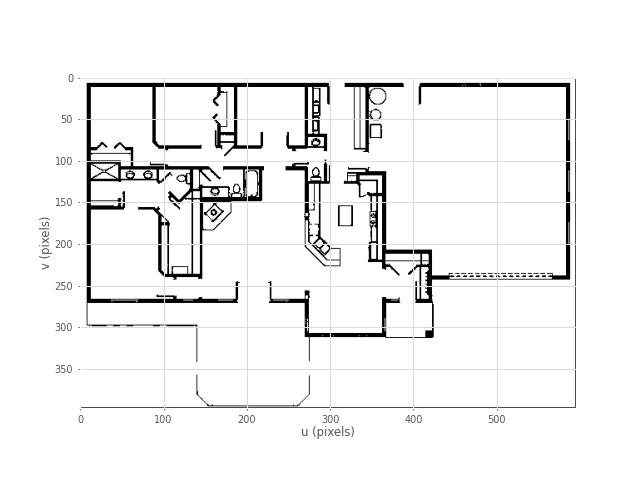

In [6]:
freespace = Image(occgrid == 0)
freespace.disp()

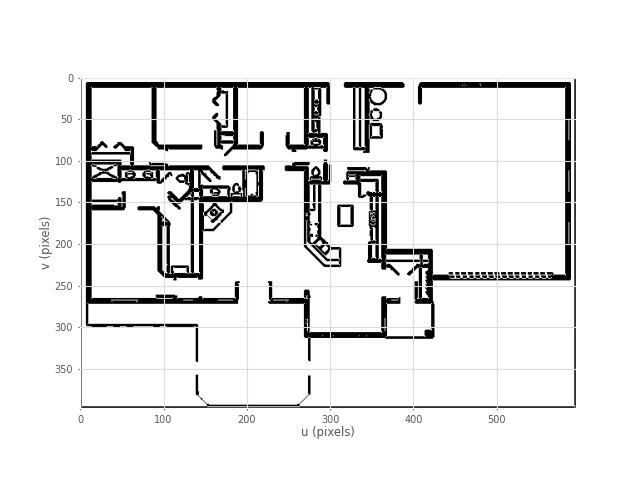

In [7]:
skeleton = freespace.thin().disp()

In [8]:
prm = PRMPlanner(occgrid=floorplan, seed=0)

PRMPlanner: 
  BinaryOccupancyGrid: 596 x 397, cell size=1, x = [0.0, 595.0], y = [0.0, 396.0], 8.8% occupied

In [9]:
prm.plan(npoints=50)

In [10]:
prm

PRMPlanner: 
  BinaryOccupancyGrid: 596 x 397, cell size=1, x = [0.0, 595.0], y = [0.0, 396.0], 8.8% occupied
  UGraph: 50 vertices, 222 edges, 12 components

plotted background


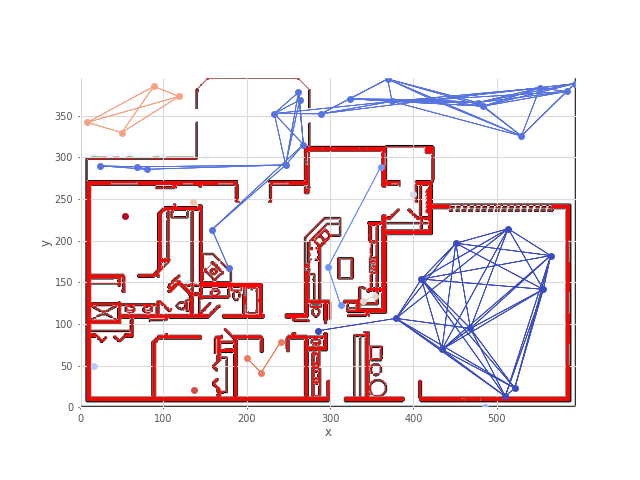

plotted roadmap


In [11]:
prm.plot()

plotted background


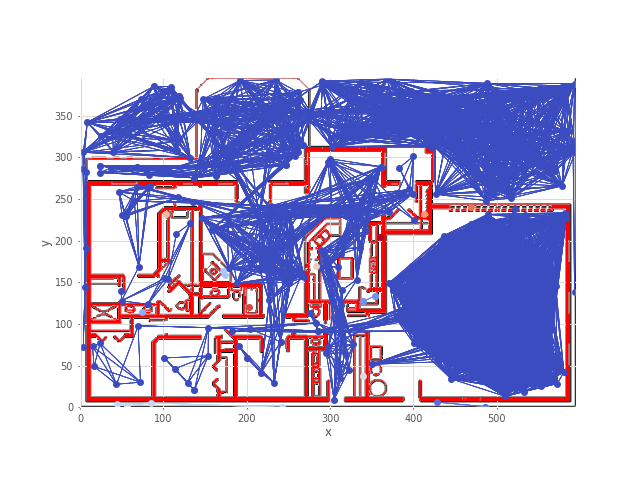

plotted roadmap


PRMPlanner: 
  BinaryOccupancyGrid: 596 x 397, cell size=1, x = [0.0, 595.0], y = [0.0, 396.0], 8.8% occupied
  UGraph: 300 vertices, 10000 edges, 13 components

In [12]:
prm.plan(npoints=300)
prm.plot()
prm

plotted background


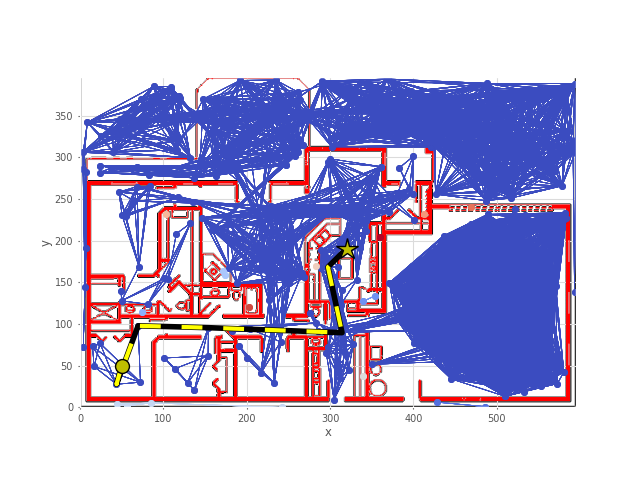

plotted roadmap


In [13]:
path = prm.query(start=places.br3, goal=places.kitchen)
prm.plot(path)

plotted background


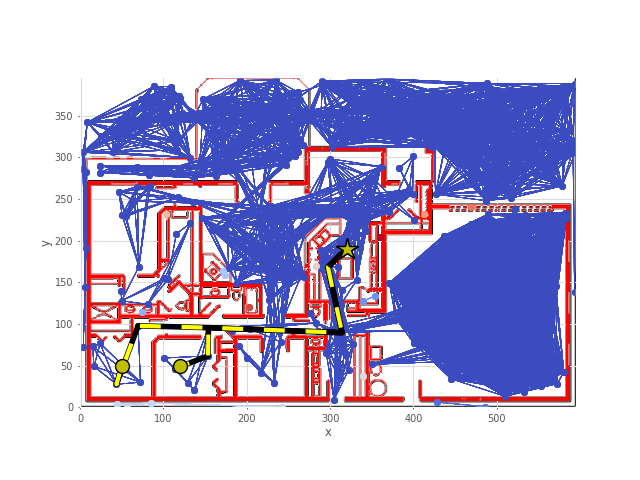

plotted roadmap


In [14]:
path = prm.query(start=places.br2, goal=places.kitchen)
prm.plot(path)